# Proyecto Cata Digital - Celler del Túria

Este notebook es una versión independiente centrada en un único tipo de neurona. El objetivo es clasificar los lotes de vino como **Estándar (0)** o **Selección (1)**, donde Selección significa `quality >= 7`.

El flujo se mantiene controlado contra fuga de información: las decisiones de preparación y ajuste se toman con `Train`, y `Test` se reserva para la evaluación final.


## Dependencias

El siguiente bloque es opcional: permite instalar las librerías del proyecto desde el notebook y regenerar `requirements.txt` si fuera necesario.


In [ ]:
#%pip install pandas numpy matplotlib seaborn scikit-learn tensorflow jupyter ipykernel
#%pip freeze > requirements.txt


## 1. Configuración, carga y partición

Se fijan semillas para que los resultados sean reproducibles, se cargan los datos desde una ruta local o desde UCI y se crea la etiqueta binaria. La partición estratificada 80/20 conserva aproximadamente la proporción de vinos Selección en ambos subconjuntos.


In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 1. Fijar semillas globales para reproducibilidad total
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

# Configuración visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 6)

# 2. Carga de datos (ruta local con fallback a repositorio oficial UCI)
URL_UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
try:
    df = pd.read_csv("../data/winequality-red.csv", sep=";")
    print("Dataset cargado desde archivo local.")
except FileNotFoundError:
    df = pd.read_csv(URL_UCI, sep=";")
    print("Dataset cargado directamente desde UCI Repository.")

# 3. Definición de la variable objetivo: Selección (quality >= 7)
df["seleccion"] = (df["quality"] >= 7).astype(int)

print(f"Dimensiones totales: {df.shape[0]} lotes y {df.shape[1]-2} variables fisicoquímicas.")
print(f"Valores nulos totales: {df.isnull().sum().sum()}")

# 4. Partición Train / Test (80/20) estratificada con random_state=42
# Usamos stratify para mantener exactamente la misma proporción de vinos Selección (~13.6%)
X = df.drop(columns=["quality", "seleccion"])
y = df["seleccion"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"\nConjunto de Entrenamiento: {X_train.shape[0]} lotes ({y_train.mean()*100:.2f}% Selección)")
print(f"Conjunto de Prueba:        {X_test.shape[0]} lotes ({y_test.mean()*100:.2f}% Selección)")


Dataset cargado directamente desde UCI Repository.
Dimensiones totales: 1599 lotes y 11 variables fisicoquímicas.
Valores nulos totales: 0

Conjunto de Entrenamiento: 1279 lotes (13.60% Selección)
Conjunto de Prueba:        320 lotes (13.44% Selección)


### Resultado esperado

Esta celda informa el tamaño del conjunto, la ausencia de nulos y la proporción de cada clase en `Train` y `Test`. La clase Selección es minoritaria, por lo que las métricas de precisión, recall y el coste de los falsos positivos son más informativos que la accuracy aislada.


## 2. Análisis exploratorio (EDA)

El EDA se ejecuta exclusivamente sobre `Train`. Primero cuantifica el desbalanceo, después calcula la correlación de Pearson de cada variable con la etiqueta y finalmente muestra boxplots de las variables más discriminantes. El cálculo de outliers usa la regla `1.5 * IQR` y sirve para conocer la calidad de las mediciones, no para eliminar datos automáticamente.


Distribución de clases en Train:
 - Estándar (0):  1105 lotes (86.40%)
 - Selección (1): 174 lotes (13.60%)

Correlación de Pearson con 'Selección' (en Train):
alcohol                 0.402
citric acid             0.206
sulphates               0.185
fixed acidity           0.111
residual sugar          0.044
pH                     -0.055
free sulfur dioxide    -0.076
chlorides              -0.090
density                -0.150
total sulfur dioxide   -0.163
volatile acidity       -0.260
Name: seleccion, dtype: float64


/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_87182/2485721956.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_87182/2485721956.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_87182/2485721956.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
/var/folders/6k/bz9hlhbx3_bcjfyfjy7j7_0m0000gn/T/ipykernel_87182/2485721956.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a Fi

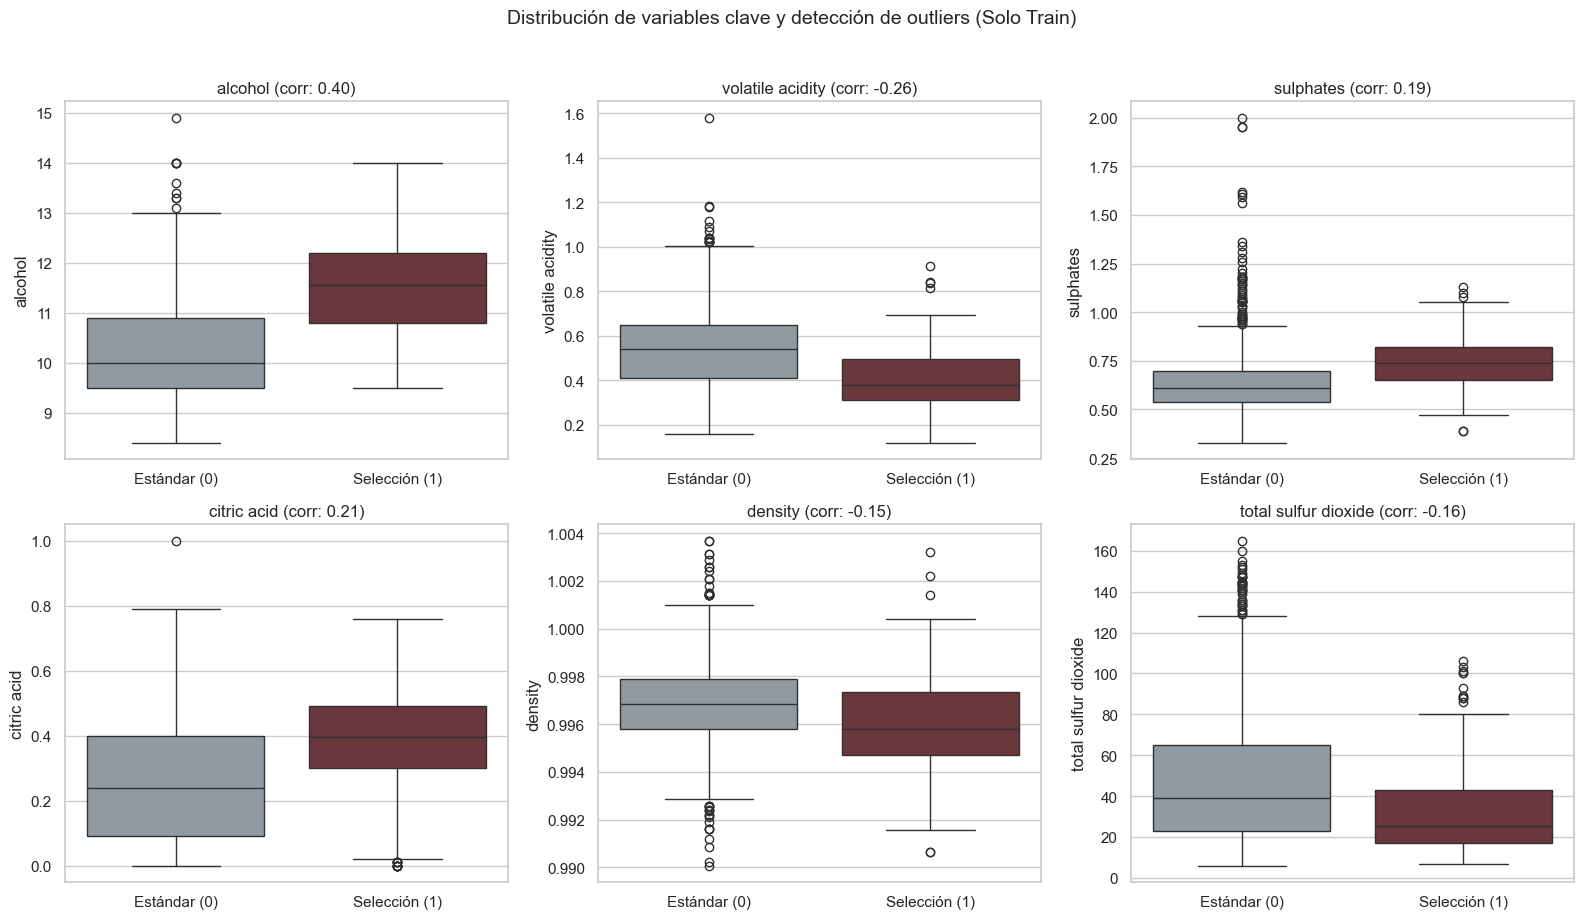


Porcentaje de valores atípicos (outliers) por variable en Train:
residual sugar          9.54
chlorides               6.33
sulphates               3.75
total sulfur dioxide    3.52
density                 3.05
fixed acidity           2.03
pH                      2.03
free sulfur dioxide     1.88
volatile acidity        1.17
alcohol                 0.94
citric acid             0.08
dtype: float64


In [2]:
# ==============================================================================
# EDA (Exclusivamente sobre el conjunto de entrenamiento)
# ==============================================================================

train_df = X_train.copy()
train_df["seleccion"] = y_train

# 1. Análisis de desbalanceo de clases
conteo = train_df["seleccion"].value_counts()
print("Distribución de clases en Train:")
print(f" - Estándar (0):  {conteo[0]} lotes ({conteo[0]/len(train_df)*100:.2f}%)")
print(f" - Selección (1): {conteo[1]} lotes ({conteo[1]/len(train_df)*100:.2f}%)")

# 2. Correlación de cada parámetro con la etiqueta Selección
correlaciones = train_df.corr()["seleccion"].drop("seleccion").sort_values(ascending=False)
print("\nCorrelación de Pearson con 'Selección' (en Train):")
print(correlaciones.round(3))

# 3. Visualización: Comparativa de las variables más discriminantes y Outliers
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
top_vars = ["alcohol", "volatile acidity", "sulphates", "citric acid", "density", "total sulfur dioxide"]

for ax, col in zip(axes.flat, top_vars):
    sns.boxplot(
        data=train_df, x="seleccion", y=col, ax=ax,
        hue="seleccion", palette=["#8c9ba5", "#722f37"], legend=False
    )
    ax.set_title(f"{col} (corr: {correlaciones[col]:.2f})")
    ax.set_xticklabels(["Estándar (0)", "Selección (1)"])
    ax.set_xlabel("")

plt.suptitle("Distribución de variables clave y detección de outliers (Solo Train)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# 4. Cuantificación de outliers (regla 1.5 * IQR en Train)
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1
outliers_pct = ((X_train < (Q1 - 1.5 * IQR)) | (X_train > (Q3 + 1.5 * IQR))).mean() * 100
print("\nPorcentaje de valores atípicos (outliers) por variable en Train:")
print(outliers_pct.sort_values(ascending=False).round(2))


### Cómo interpretar el EDA

Las correlaciones orientan la selección de variables y de signos en la neurona McCulloch-Pitts. Los boxplots permiten comparar la distribución de Estándar y Selección, mientras que el porcentaje de outliers advierte de variables que pueden influir mucho en modelos sensibles a escala.


## 3. Evaluación técnica y de negocio

`evaluar_modelo` calcula accuracy, precisión, recall y la matriz de confusión. Luego proyecta los aciertos y errores a 1.600 lotes anuales. Cada verdadero positivo aporta 1.200 €, mientras que cada falso positivo cuesta 2.500 €, de modo que el umbral de decisión se calibra con el beneficio neto en `Train`.


In [3]:
# ==============================================================================
# FUNCIÓN COMÚN DE EVALUACIÓN TÉCNICA Y DE NEGOCIO
# ==============================================================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

# Supuestos económicos del cliente (Celler del Túria)
LOTES_ANUALES = 1600
FACTOR_ESCALA = LOTES_ANUALES / len(y_test)  # ~5.0 (1600 / 320)
SOBREPRECIO_SELECCION = 1200  # +40% sobre 3.000 € por lote correcto (VP)
COSTE_FALSO_POSITIVO = 2500   # Vino mediocre etiquetado como Selección (FP)

resultados_modelos = []

def evaluar_modelo(nombre_modelo, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    
    # Matriz de confusión: [[VN, FP], [FN, VP]]
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    
    # Escalado anual (de ~320 lotes de test a 1.600 lotes/año)
    tp_anual = round(tp * FACTOR_ESCALA)
    fp_anual = round(fp * FACTOR_ESCALA)
    fn_anual = round(fn * FACTOR_ESCALA)
    tn_anual = round(tn * FACTOR_ESCALA)
    
    # Impacto económico neto anual:
    # Ganamos +1.200€ por cada Selección real detectado (VP)
    # Perdemos -2.500€ por cada mediocre colado como Selección (FP)
    # (Los FN no restan caja directa, son coste de oportunidad = fn_anual * 1200€)
    ingresos_extra = tp_anual * SOBREPRECIO_SELECCION
    perdidas_marca = fp_anual * COSTE_FALSO_POSITIVO
    beneficio_neto = ingresos_extra - perdidas_marca
    coste_oportunidad = fn_anual * SOBREPRECIO_SELECCION
    
    print(f"\n{'='*60}")
    print(f"RESULTADOS: {nombre_modelo}")
    print(f"{'='*60}")
    print(f"Accuracy:  {acc*100:.2f}% | Precisión (Selección): {prec*100:.2f}% | Recall (Selección): {rec*100:.2f}%")
    print(f"\nMatriz de Confusión (Test - {len(y_true)} lotes):")
    print(f"  Verdaderos Negativos (Estándar OK):  {tn:3d} | Falsos Positivos (ERROR CARO): {fp:3d}")
    print(f"  Falsos Negativos (Oportunidad perd.): {fn:3d} | Verdaderos Positivos (Sel. OK):  {tp:3d}")
    print(f"\nProyección Anual ({LOTES_ANUALES} lotes/año):")
    print(f"  - Lotes Selección bien detectados: {tp_anual} lotes  --> +{ingresos_extra:,.0f} €")
    print(f"  - Lotes mediocres colados (FP):    {fp_anual} lotes  --> -{perdidas_marca:,.0f} €")
    print(f"  - Lotes buenos perdidos (FN):       {fn_anual} lotes  --> ({coste_oportunidad:,.0f} € no capturados)")
    print(f"  >>> IMPACTO NETO ANUAL ESTIMADO:    {beneficio_neto:+,.0f} € / año")
    
    resultados_modelos.append({
        "Modelo": nombre_modelo,
        "Accuracy (%)": round(acc * 100, 2),
        "Precisión (%)": round(prec * 100, 2),
        "Recall (%)": round(rec * 100, 2),
        "VP_anual": tp_anual,
        "FP_anual": fp_anual,
        "FN_anual": fn_anual,
        "Beneficio_Neto_EUR": beneficio_neto
    })


## 4. Neurona de McCulloch-Pitts (1943)

Esta neurona representa un clasificador por reglas. Cada variable se convierte en 0/1 según si cumple un criterio de perfil óptimo: valores altos para variables positivas y valores bajos para variables negativas. La activación es una suma de condiciones y se predice Selección cuando la suma alcanza `theta`.


In [5]:
# ==============================================================================
# MODELO 1: NEURONA DE McCULLOCH-PITTS (1943)
# ==============================================================================

# 1. Selección de variables discriminantes (basadas en correlaciones del EDA en Train)
# Distinguimos variables positivas (más es mejor) y negativas (menos es mejor)
vars_positivas = ["alcohol", "sulphates", "citric acid", "fixed acidity"]
vars_negativas = ["volatile acidity", "density", "total sulfur dioxide", "chlorides"]
vars_mp = vars_positivas + vars_negativas

# 2. Cálculo de umbrales de binarización (SOLO sobre X_train)
# Usamos la mediana de los vinos Selección en Train como referencia de "perfil óptimo"
umbrales_mp = {}
for col in vars_positivas:
    umbrales_mp[col] = X_train.loc[y_train == 1, col].median()
for col in vars_negativas:
    umbrales_mp[col] = X_train.loc[y_train == 1, col].median()

def binarizar_mp(df_in):
    bin_df = pd.DataFrame(index=df_in.index)
    for col in vars_positivas:
        bin_df[col] = (df_in[col] >= umbrales_mp[col]).astype(int)
    for col in vars_negativas:
        # 1 si está por debajo o igual al umbral (ej. baja acidez volátil = bueno)
        bin_df[col] = (df_in[col] <= umbrales_mp[col]).astype(int)
    return bin_df

X_train_bin = binarizar_mp(X_train)
X_test_bin = binarizar_mp(X_test)

# 3. Búsqueda del umbral de disparo (theta) óptimo en TRAIN según criterio de negocio
# La neurona M-P suma las entradas binarias: y = 1 si sum(x_i) >= theta
mejor_theta = None
mejor_beneficio_train = -np.inf

for theta in range(1, len(vars_mp) + 1):
    pred_tr = (X_train_bin.sum(axis=1) >= theta).astype(int)
    tn_tr, fp_tr, fn_tr, tp_tr = confusion_matrix(y_train, pred_tr).ravel()
    # Calculamos beneficio neto en train para elegir el theta más rentable
    beneficio_tr = (tp_tr * SOBREPRECIO_SELECCION) - (fp_tr * COSTE_FALSO_POSITIVO)
    print(f"Theta = {theta}/{len(vars_mp)} -> Train VP: {tp_tr:3d}, FP: {fp_tr:3d} | Beneficio Train: {beneficio_tr:+9,.0f} €")
    if beneficio_tr > mejor_beneficio_train:
        mejor_beneficio_train = beneficio_tr
        mejor_theta = theta

print(f"\nUmbral de disparo elegido (optimizado en Train): theta = {mejor_theta} de {len(vars_mp)} condiciones")

# 4. Evaluación final en TEST
y_pred_mp = (X_test_bin.sum(axis=1) >= mejor_theta).astype(int)
evaluar_modelo("1. Neurona McCulloch-Pitts (1943)", y_test, y_pred_mp)


Theta = 1/8 -> Train VP: 172, FP: 883 | Beneficio Train: -2,001,100 €
Theta = 2/8 -> Train VP: 163, FP: 595 | Beneficio Train: -1,291,900 €
Theta = 3/8 -> Train VP: 142, FP: 366 | Beneficio Train:  -744,600 €
Theta = 4/8 -> Train VP: 119, FP: 194 | Beneficio Train:  -342,200 €
Theta = 5/8 -> Train VP:  68, FP:  78 | Beneficio Train:  -113,400 €
Theta = 6/8 -> Train VP:  33, FP:  22 | Beneficio Train:   -15,400 €
Theta = 7/8 -> Train VP:   9, FP:   2 | Beneficio Train:    +5,800 €
Theta = 8/8 -> Train VP:   0, FP:   0 | Beneficio Train:        +0 €

Umbral de disparo elegido (optimizado en Train): theta = 7 de 8 condiciones

RESULTADOS: 1. Neurona McCulloch-Pitts (1943)
Accuracy:  88.12% | Precisión (Selección): 100.00% | Recall (Selección): 11.63%

Matriz de Confusión (Test - 320 lotes):
  Verdaderos Negativos (Estándar OK):  277 | Falsos Positivos (ERROR CARO):   0
  Falsos Negativos (Oportunidad perd.):  38 | Verdaderos Positivos (Sel. OK):    5

Proyección Anual (1600 lotes/año):
  

## Lectura de resultados

La salida muestra el beneficio en `Train` para cada `theta` y el umbral elegido. Después, la evaluación sobre `Test` permite comprobar si la regla generaliza. Un `theta` bajo aumenta la sensibilidad pero puede generar más falsos positivos; uno alto es más conservador y puede aumentar los falsos negativos.

Este modelo es fácil de explicar a dirección, aunque pierde información al binarizar las variables y no aprende pesos diferenciados.


## Conclusión

Este archivo puede ejecutarse de principio a fin de forma independiente. Para comparar formalmente los tres enfoques, consulta los resultados de cada notebook usando el mismo `SEED`, partición y función de evaluación.
